# Notebook 4 – Univariate Analysis
**File:** `04_Univariate_Analysis.ipynb`

## Objective
Analyze one variable at a time: its typical value, spread, distribution, unusual values, and category balance. Examples use the Telco Customer Churn dataset.

## Setup and load data

This notebook uses the IBM Telco Customer Churn dataset. Put `WA_Fn-UseC_-Telco-Customer-Churn.csv` beside this notebook, or change `DATA_PATH` below.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")

DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
DATA_PATH = Path(
    r"C:\Users\ramki\sprint_4\dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv"
)
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found at {DATA_PATH.resolve()}. Update DATA_PATH.")
df = pd.read_csv(DATA_PATH)
if "TotalCharges" in df:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Shape:", df.shape)
display(df.head())


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Identify numerical and categorical variables
**Concept:** Numerical columns measure quantities; categorical columns represent groups. Numeric-looking identifiers should not be treated as measurements.

**Example:** `tenure` and `MonthlyCharges` are numeric; `Contract` and `InternetService` are categorical.

**AI/ML relevance:** Feature type determines which summaries, plots, encoders, and preprocessing methods are appropriate.

In [17]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [c for c in numeric_cols if c.lower() not in {"customerid", "customer_id", "id"}]
categorical_cols = df.select_dtypes(include=["object", "str", "category", "bool"]).columns.tolist()
print("Numerical:", numeric_cols)
print("Categorical:", categorical_cols)

Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


## 2. Numerical descriptive statistics
Calculate mean, median, mode, minimum, maximum, range, variance, standard deviation, quartiles, percentiles, skewness, and kurtosis.

- Mean vs median can reveal skew.
- Range, variance, and standard deviation describe spread.
- Quartiles and percentiles describe positions in the distribution.
- Positive skewness indicates a longer right tail; negative skewness a longer left tail.
- Pandas kurtosis is excess kurtosis.

**Example:** `MonthlyCharges` can show the typical bill and variability.

In [18]:
def summarize_numeric(series):
    s = pd.to_numeric(series, errors="coerce").dropna()
    modes = s.mode()
    return pd.Series({
        "count": s.count(), "mean": s.mean(), "median": s.median(),
        "mode": modes.iloc[0] if not modes.empty else np.nan,
        "minimum": s.min(), "maximum": s.max(), "range": s.max()-s.min(),
        "variance": s.var(), "std_dev": s.std(),
        "Q1 (25%)": s.quantile(.25), "Q2 (50%)": s.quantile(.50),
        "Q3 (75%)": s.quantile(.75), "10th percentile": s.quantile(.10),
        "90th percentile": s.quantile(.90), "skewness": s.skew(),
        "kurtosis (excess)": s.kurt()
    })
summary = pd.DataFrame({c: summarize_numeric(df[c]) for c in numeric_cols}).T
display(summary.round(3))

,count,mean,median,mode,minimum,maximum,range,variance,std_dev,Q1 (25%),Q2 (50%),Q3 (75%),10th percentile,90th percentile,skewness,kurtosis (excess)
SeniorCitizen,7043.0,0.162,0.000,0.00,0.00,1.00,1.0,0.136,0.369,0.00,0.000,0.000,0.00,1.00,1.834,1.363
tenure,7043.0,32.371,29.000,1.00,0.00,72.00,72.0,603.168,24.559,9.00,29.000,55.000,2.00,69.00,0.240,-1.387
MonthlyCharges,7043.0,64.762,70.350,20.05,18.25,118.75,100.5,905.411,30.090,35.50,70.350,89.850,20.05,102.60,-0.221,-1.257
TotalCharges,7032.0,2283.300,1397.475,20.20,18.80,8684.80,8666.0,5138252.407,2266.771,401.45,1397.475,3794.738,84.60,5976.64,0.962,-0.232


### Output explanation
Read the table feature by feature. A mean above the median may indicate right skew; a large standard deviation indicates greater variation. Check minimum/maximum for implausible values and use quartiles to describe the middle 50%. Actual findings depend on the CSV.

## 3. Histogram, KDE/density plot, and box plot
A histogram shows counts across intervals; KDE smooths the distribution; a box plot summarizes median, quartiles, and potential outliers. A box-plot outlier is not automatically a data error.

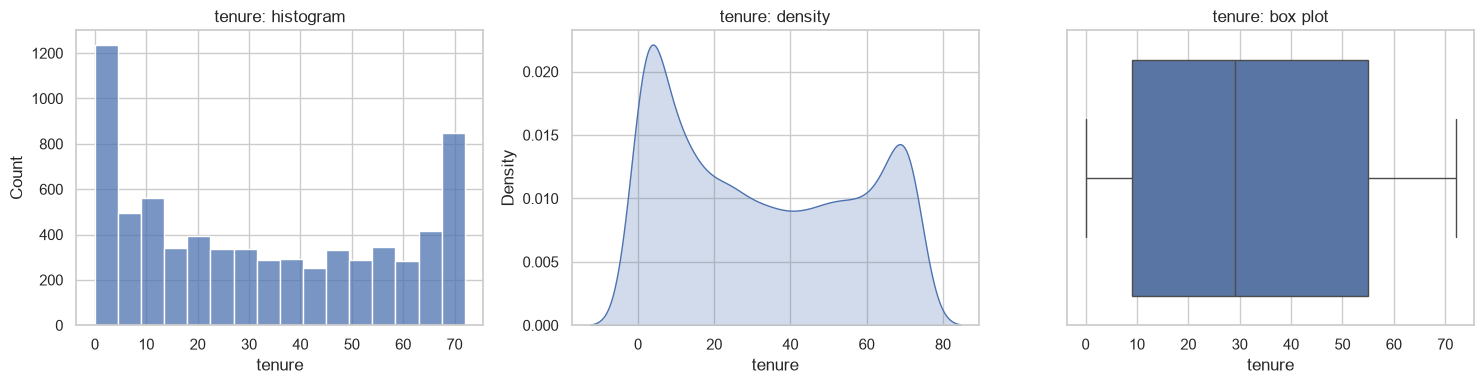

tenure: mean=32.37, median=29.00, skew=0.24


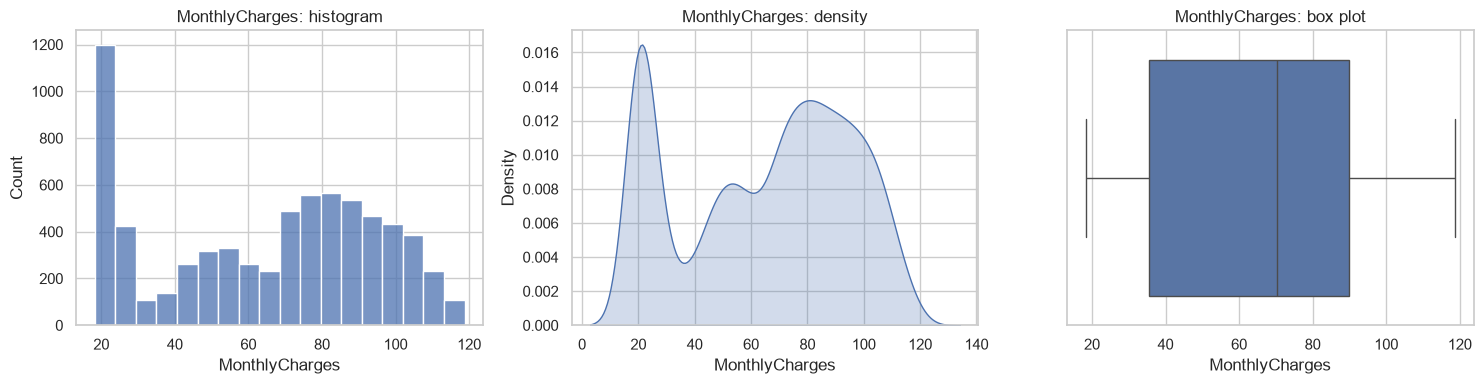

MonthlyCharges: mean=64.76, median=70.35, skew=-0.22


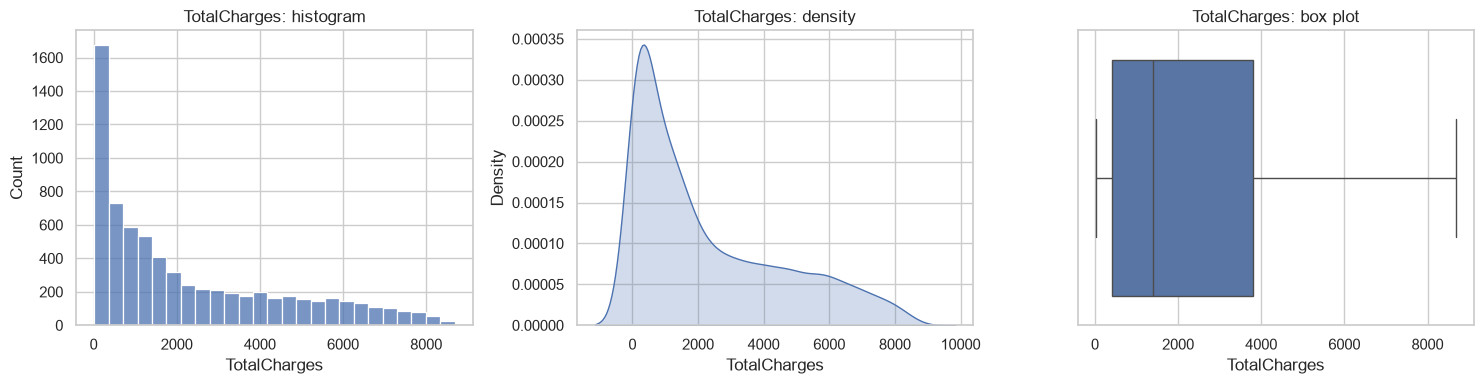

TotalCharges: mean=2283.30, median=1397.47, skew=0.96


In [19]:
plot_cols = [c for c in ["tenure", "MonthlyCharges", "TotalCharges"] if c in df.columns]
if not plot_cols: plot_cols = numeric_cols[:3]
for col in plot_cols:
    x = pd.to_numeric(df[col], errors="coerce").dropna()
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    sns.histplot(x, ax=ax[0]); ax[0].set_title(f"{col}: histogram")
    sns.kdeplot(x, fill=True, ax=ax[1]); ax[1].set_title(f"{col}: density")
    sns.boxplot(x=x, ax=ax[2]); ax[2].set_title(f"{col}: box plot")
    plt.tight_layout(); plt.show()
    print(f"{col}: mean={x.mean():.2f}, median={x.median():.2f}, skew={x.skew():.2f}")

### Output explanation
Describe shape (symmetric, skewed, or multi-peaked), clustering, and possible outliers. Consider transformations only after understanding the distribution and the feature's meaning.

## 4. Categorical frequency and percentage distribution
Frequency counts show how often each category occurs; percentages make categories easier to compare. Unique-value counts also reveal high-cardinality columns.

**Example:** `Contract`, `PaymentMethod`, and `InternetService`.

**AI/ML relevance:** Rare categories and imbalanced target classes can affect encoding and model evaluation.

In [20]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print("Unique non-null values:", df[col].nunique(dropna=True))
    counts = df[col].value_counts(dropna=False)
    pct = df[col].value_counts(dropna=False, normalize=True).mul(100)
    display(pd.DataFrame({"frequency": counts, "percentage": pct.round(2)}))


--- customerID ---
Unique non-null values: 7043


,frequency,percentage
customerID,,
7590-VHVEG,1,0.01
5575-GNVDE,1,0.01
3668-QPYBK,1,0.01
7795-CFOCW,1,0.01
9237-HQITU,1,0.01
...,...,...
6840-RESVB,1,0.01
2234-XADUH,1,0.01
4801-JZAZL,1,0.01



--- gender ---
Unique non-null values: 2


,frequency,percentage
gender,,
Male,3555,50.48
Female,3488,49.52



--- Partner ---
Unique non-null values: 2


...

,frequency,percentage
PaperlessBilling,,
Yes,4171,59.22
No,2872,40.78



--- PaymentMethod ---
Unique non-null values: 4


,frequency,percentage
PaymentMethod,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61



--- Churn ---
Unique non-null values: 2


,frequency,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


## 5. Bar/count plots and pie chart
Bar/count plots are useful for comparing category sizes. Pie charts are best limited to a few categories.

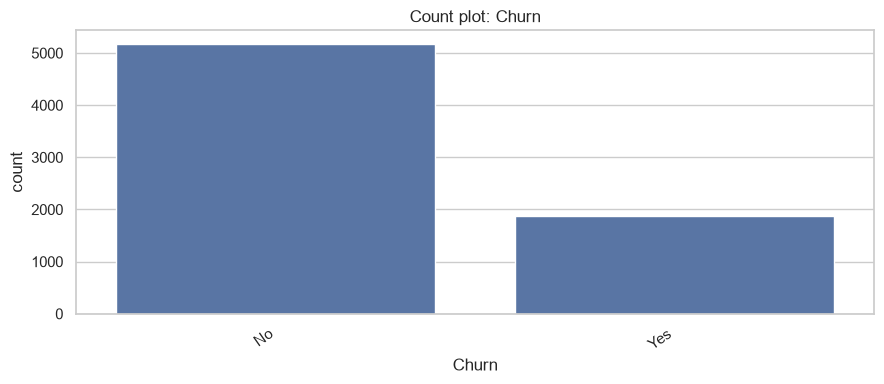

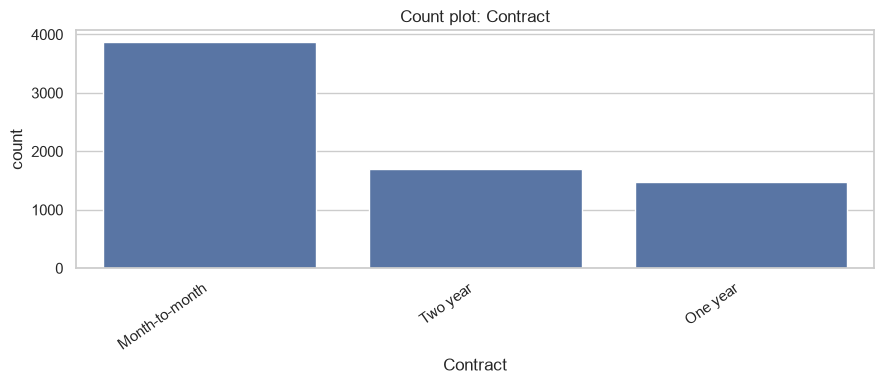

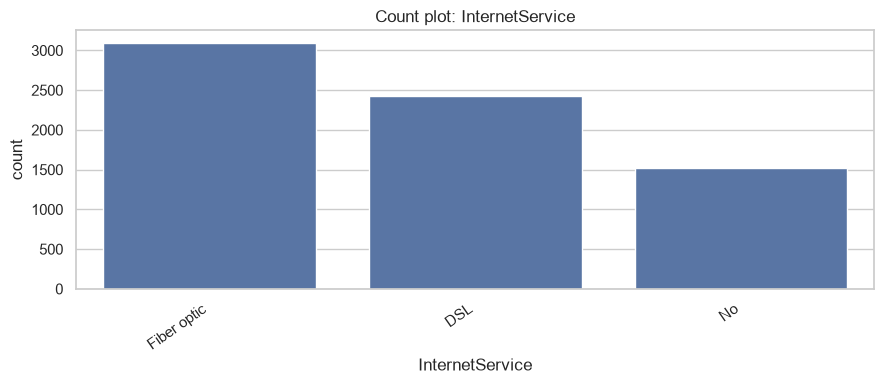

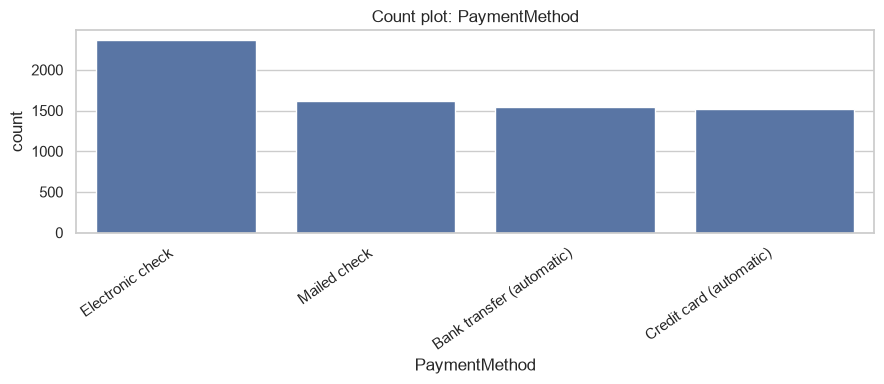

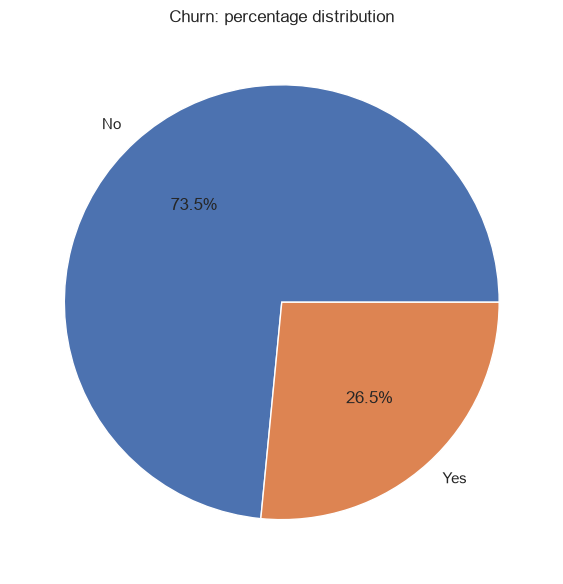

In [21]:
plot_cols = [c for c in ["Churn", "Contract", "InternetService", "PaymentMethod"] if c in df.columns]
if not plot_cols: plot_cols = categorical_cols[:4]
for col in plot_cols:
    temp = df[col].astype("string").fillna("<Missing>")
    order = temp.value_counts().index
    plt.figure(figsize=(9, 4))
    sns.countplot(x=temp, order=order)
    plt.title(f"Count plot: {col}"); plt.xticks(rotation=35, ha="right")
    plt.tight_layout(); plt.show()
pie_col = "Churn" if "Churn" in df.columns else (plot_cols[0] if plot_cols else None)
if pie_col and df[pie_col].nunique(dropna=False) <= 6:
    df[pie_col].astype("string").fillna("<Missing>").value_counts().plot(
        kind="pie", autopct="%1.1f%%", ylabel="", title=f"{pie_col}: percentage distribution", figsize=(6,6))
    plt.tight_layout(); plt.show()

## 6. Findings for important variables
For every important feature, document: (1) typical value or most common category, (2) spread, (3) distribution shape, (4) unusual values/categories, and (5) implications for preprocessing or modeling.

If `Churn` exists, inspect class balance. Accuracy alone may be misleading when the target is imbalanced; consider precision, recall, F1, and a confusion matrix during modeling.

## Conclusion
Summarize the key distribution patterns, highly variable or skewed numerical features, unusual values to validate, and dominant categories. Do not infer causation from univariate analysis.

In [22]:
if "Churn" in df.columns:
    counts = df["Churn"].value_counts(dropna=False)
    pct = df["Churn"].value_counts(dropna=False, normalize=True).mul(100)
    display(pd.DataFrame({"count": counts, "percentage": pct.round(2)}))
else:
    print("No Churn column found.")

,count,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54
